In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df_products = pd.read_csv('pharmacy_products.csv')
df_batches = pd.read_csv('pharmacy_inventory_batches.csv')
df_sales = pd.read_csv('pharmacy_sales_transactions.csv')

In [4]:
df_sales['transaction_date'] = pd.to_datetime(df_sales['transaction_date'])
df_batches['expiry_date'] = pd.to_datetime(df_batches['expiry_date'])

In [5]:
# Aggregate Daily Sales per Product
daily_sales = (
    df_sales.groupby(['product_id', 'transaction_date'])
    .agg(
        daily_units=('units_sold', 'sum'),
        had_clearance_promo=('clearance_discount_applied', 'max'),
    )
    .reset_index()
)

In [6]:
# Create a Complete Daily Grid (Fill zero-sales days)

all_dates = pd.date_range(
    start=daily_sales['transaction_date'].min(),
    end=daily_sales['transaction_date'].max(),
    freq='D',
)
all_products = df_products['product_id'].unique()

full_grid = (
    pd.MultiIndex.from_product(
        [all_products, all_dates], names=['product_id', 'transaction_date']
    )
    .to_frame()
    .reset_index(drop=True)
)

daily_df = full_grid.merge(
    daily_sales, on=['product_id', 'transaction_date'], how='left'
)
daily_df['daily_units'] = daily_df['daily_units'].fillna(0)
daily_df['had_clearance_promo'] = daily_df['had_clearance_promo'].fillna(0)

# Merge static product features
daily_df = daily_df.merge(
    df_products[[
        'product_id',
        'category',
        'unit_cost_usd',
        'selling_price_usd',
        'supplier_lead_time_days',
    ]],
    on='product_id',
    how='left',
)

In [7]:
# Generate Lag and Rolling Window Features (with shift(1) to prevent look-ahead leakage)


daily_df = daily_df.sort_values(
    ['product_id', 'transaction_date']
).reset_index(drop=True)

# Historical Lags
daily_df['lag_1d'] = daily_df.groupby('product_id')['daily_units'].shift(1)
daily_df['lag_7d'] = daily_df.groupby('product_id')['daily_units'].shift(7)
daily_df['lag_14d'] = daily_df.groupby('product_id')['daily_units'].shift(14)

# Rolling Means (Trend Indicators)
daily_df['rolling_mean_7d'] = (
    daily_df.groupby('product_id')['daily_units']
    .shift(1)
    .rolling(window=7, min_periods=1)
    .mean()
)
daily_df['rolling_mean_14d'] = (
    daily_df.groupby('product_id')['daily_units']
    .shift(1)
    .rolling(window=14, min_periods=1)
    .mean()
)
daily_df['rolling_mean_30d'] = (
    daily_df.groupby('product_id')['daily_units']
    .shift(1)
    .rolling(window=30, min_periods=1)
    .mean()
)

# Rolling Volatility (Demand Variability)
daily_df['rolling_std_7d'] = (
    daily_df.groupby('product_id')['daily_units']
    .shift(1)
    .rolling(window=7, min_periods=1)
    .std()
    .fillna(0)
)

# Calendar Features
daily_df['day_of_week'] = daily_df['transaction_date'].dt.dayofweek
daily_df['is_weekend'] = daily_df['day_of_week'].isin([5, 6]).astype(int)
daily_df['month'] = daily_df['transaction_date'].dt.month

In [9]:
daily_df.head()

,product_id,transaction_date,daily_units,had_clearance_promo,category,unit_cost_usd,selling_price_usd,supplier_lead_time_days,lag_1d,lag_7d,lag_14d,rolling_mean_7d,rolling_mean_14d,rolling_mean_30d,rolling_std_7d,day_of_week,is_weekend,month
0,PRD001,2025-10-01,0.0,0.0,Antibiotics,29.32,38.7,7,NaN,NaN,NaN,NaN,NaN,NaN,0.0,2,0,10
1,PRD001,2025-10-02,0.0,0.0,Antibiotics,29.32,38.7,7,0.0,NaN,NaN,0.00,0.00,0.00,0.0,3,0,10
2,PRD001,2025-10-03,0.0,0.0,Antibiotics,29.32,38.7,7,0.0,NaN,NaN,0.00,0.00,0.00,0.0,4,0,10
3,PRD001,2025-10-04,3.0,0.0,Antibiotics,29.32,38.7,7,0.0,NaN,NaN,0.00,0.00,0.00,0.0,5,1,10
4,PRD001,2025-10-05,0.0,0.0,Antibiotics,29.32,38.7,7,3.0,NaN,NaN,0.75,0.75,0.75,1.5,6,1,10


In [10]:
# One-Hot Encode Categorical Variables

daily_df = pd.get_dummies(daily_df, columns=['category'], drop_first=True)

# Drop initial lookback rows containing NaN values from lag operations
model_data = daily_df.dropna().reset_index(drop=True)

print(
    f'Dataset prepared for ML: {model_data.shape[0]:,} rows and'
    f' {model_data.shape[1]} features.'
)
display(model_data.head(3))

Dataset prepared for ML: 16,168 rows and 24 features.


,product_id,transaction_date,daily_units,had_clearance_promo,unit_cost_usd,selling_price_usd,supplier_lead_time_days,lag_1d,lag_7d,lag_14d,...,day_of_week,is_weekend,month,category_Antidiabetics,category_Cardiovascular,category_Dermatology & Topical,category_Gastrointestinal,category_Pain Relief & Anti-inflammatory,category_Respiratory,category_Vitamins & Supplements
0,PRD001,2025-10-15,7.0,0.0,29.32,38.7,7,0.0,0.0,0.0,...,2,0,10,False,False,False,False,False,False,False
1,PRD001,2025-10-16,5.0,0.0,29.32,38.7,7,7.0,7.0,0.0,...,3,0,10,False,False,False,False,False,False,False
2,PRD001,2025-10-17,6.0,0.0,29.32,38.7,7,5.0,0.0,0.0,...,4,0,10,False,False,False,False,False,False,False


# Chronological Split, Model Training & Evaluation

In [12]:
# Set cutoff date: Train on first historical period, evaluate on final 60 days
split_date = model_data['transaction_date'].max() - pd.Timedelta(days=60)

train_df = model_data[model_data['transaction_date'] < split_date]
test_df = model_data[model_data['transaction_date'] >= split_date]

In [14]:
train_df

,product_id,transaction_date,daily_units,had_clearance_promo,unit_cost_usd,selling_price_usd,supplier_lead_time_days,lag_1d,lag_7d,lag_14d,...,day_of_week,is_weekend,month,category_Antidiabetics,category_Cardiovascular,category_Dermatology & Topical,category_Gastrointestinal,category_Pain Relief & Anti-inflammatory,category_Respiratory,category_Vitamins & Supplements
0,PRD001,2025-10-15,7.0,0.0,29.32,38.70,7,0.0,0.0,0.0,...,2,0,10,False,False,False,False,False,False,False
1,PRD001,2025-10-16,5.0,0.0,29.32,38.70,7,7.0,7.0,0.0,...,3,0,10,False,False,False,False,False,False,False
2,PRD001,2025-10-17,6.0,0.0,29.32,38.70,7,5.0,0.0,0.0,...,4,0,10,False,False,False,False,False,False,False
3,PRD001,2025-10-18,0.0,0.0,29.32,38.70,7,6.0,6.0,3.0,...,5,1,10,False,False,False,False,False,False,False
4,PRD001,2025-10-19,4.0,0.0,29.32,38.70,7,0.0,6.0,0.0,...,6,1,10,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16102,PRD043,2026-08-21,0.0,0.0,13.03,26.03,10,7.0,7.0,8.0,...,4,0,8,False,False,True,False,False,False,False
16103,PRD043,2026-08-22,0.0,0.0,13.03,26.03,10,0.0,8.0,7.0,...,5,1,8,False,False,True,False,False,False,False
16104,PRD043,2026-08-23,5.0,0.0,13.03,26.03,10,0.0,6.0,3.0,...,6,1,8,False,False,True,False,False,False,False
16105,PRD043,2026-08-24,0.0,0.0,13.03,26.03,10,5.0,3.0,0.0,...,0,0,8,False,False,True,False,False,False,False


In [15]:
test_df

,product_id,transaction_date,daily_units,had_clearance_promo,unit_cost_usd,selling_price_usd,supplier_lead_time_days,lag_1d,lag_7d,lag_14d,...,day_of_week,is_weekend,month,category_Antidiabetics,category_Cardiovascular,category_Dermatology & Topical,category_Gastrointestinal,category_Pain Relief & Anti-inflammatory,category_Respiratory,category_Vitamins & Supplements
315,PRD001,2026-08-26,0.0,0.0,29.32,38.70,7,0.0,9.0,4.0,...,2,0,8,False,False,False,False,False,False,False
316,PRD001,2026-08-27,0.0,0.0,29.32,38.70,7,0.0,0.0,3.0,...,3,0,8,False,False,False,False,False,False,False
317,PRD001,2026-08-28,11.0,0.0,29.32,38.70,7,0.0,0.0,0.0,...,4,0,8,False,False,False,False,False,False,False
318,PRD001,2026-08-29,10.0,0.0,29.32,38.70,7,11.0,9.0,0.0,...,5,1,8,False,False,False,False,False,False,False
319,PRD001,2026-08-30,0.0,0.0,29.32,38.70,7,10.0,0.0,7.0,...,6,1,8,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16163,PRD043,2026-10-21,0.0,0.0,13.03,26.03,10,6.0,0.0,0.0,...,2,0,10,False,False,True,False,False,False,False
16164,PRD043,2026-10-22,1.0,0.0,13.03,26.03,10,0.0,0.0,0.0,...,3,0,10,False,False,True,False,False,False,False
16165,PRD043,2026-10-23,7.0,0.0,13.03,26.03,10,1.0,4.0,0.0,...,4,0,10,False,False,True,False,False,False,False
16166,PRD043,2026-10-24,0.0,0.0,13.03,26.03,10,7.0,11.0,3.0,...,5,1,10,False,False,True,False,False,False,False


In [16]:
# Define feature columns and target variable


drop_cols = ['product_id', 'transaction_date', 'daily_units']
feature_cols = [c for c in model_data.columns if c not in drop_cols]
target = 'daily_units'

X_train, y_train = train_df[feature_cols], train_df[target]
X_test, y_test = test_df[feature_cols], test_df[target]

print(
    f'Training observations: {len(X_train):,} ({train_df["transaction_date"].min().date()} to {train_df["transaction_date"].max().date()})'
)
print(
    f'Testing observations: {len(X_test):,} ({test_df["transaction_date"].min().date()} to {test_df["transaction_date"].max().date()})'
)

Training observations: 13,545 (2025-10-15 to 2026-08-25)
Testing observations: 2,623 (2026-08-26 to 2026-10-25)


In [20]:
# ==============================================================================
# WEEKLY DEMAND FORECASTING PIPELINE (FIXED)
# ==============================================================================
import pandas as pd
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Resample Daily Units to Weekly Totals
weekly_units = (
    daily_df.groupby(['product_id', pd.Grouper(key='transaction_date', freq='W-MON')])
    .agg(weekly_units=('daily_units', 'sum'))
    .reset_index()
)

# 2. Merge Product Metadata (category, prices) from df_products
weekly_df = weekly_units.merge(
    df_products[['product_id', 'category', 'unit_cost_usd', 'selling_price_usd']], 
    on='product_id', 
    how='left'
)

# 3. Engineer Weekly Lags & Features
weekly_df = weekly_df.sort_values(['product_id', 'transaction_date']).reset_index(drop=True)

weekly_df['lag_1w'] = weekly_df.groupby('product_id')['weekly_units'].shift(1)
weekly_df['lag_2w'] = weekly_df.groupby('product_id')['weekly_units'].shift(2)
weekly_df['rolling_mean_4w'] = weekly_df.groupby('product_id')['weekly_units'].shift(1).rolling(4, min_periods=1).mean()
weekly_df['month'] = weekly_df['transaction_date'].dt.month

# One-Hot Encode Category on Weekly DataFrame
weekly_df = pd.get_dummies(weekly_df, columns=['category'], drop_first=True)
weekly_model_data = weekly_df.dropna().reset_index(drop=True)

# 4. Chronological Train/Test Split (Test on final 8 weeks)
split_date_weekly = weekly_model_data['transaction_date'].max() - pd.Timedelta(weeks=8)

train_w = weekly_model_data[weekly_model_data['transaction_date'] < split_date_weekly].copy()
test_w = weekly_model_data[weekly_model_data['transaction_date'] >= split_date_weekly].copy()

# Product Target Encoding (Calculated strictly on train_w)
prod_weekly_mean = train_w.groupby('product_id')['weekly_units'].mean().to_dict()
train_w['product_hist_weekly_mean'] = train_w['product_id'].map(prod_weekly_mean)
test_w['product_hist_weekly_mean'] = test_w['product_id'].map(prod_weekly_mean).fillna(train_w['weekly_units'].mean())

# Define Features and Target
drop_cols = ['product_id', 'transaction_date', 'weekly_units']
feature_cols_w = [c for c in train_w.columns if c not in drop_cols]

X_train_w, y_train_w = train_w[feature_cols_w], train_w['weekly_units']
X_test_w, y_test_w = test_w[feature_cols_w], test_w['weekly_units']

# 5. Train Poisson Model
hgb_weekly = HistGradientBoostingRegressor(loss='poisson', max_iter=300, learning_rate=0.03, random_state=42)
hgb_weekly.fit(X_train_w, y_train_w)

preds_w = np.clip(hgb_weekly.predict(X_test_w), 0, None)

print("=== WEEKLY DEMAND FORECAST RESULTS ===")
print(f"MAE  (Weekly Units): {mean_absolute_error(y_test_w, preds_w):.3f}")
print(f"RMSE (Weekly Units): {np.sqrt(mean_squared_error(y_test_w, preds_w)):.3f}")
print(f"R2 Score           : {r2_score(y_test_w, preds_w):.3f}")

=== WEEKLY DEMAND FORECAST RESULTS ===
MAE  (Weekly Units): 9.426
RMSE (Weekly Units): 12.132
R2 Score           : 0.190


C:\Users\USER\AppData\Local\Temp\ipykernel_5724\2114253828.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette="Blues_r")


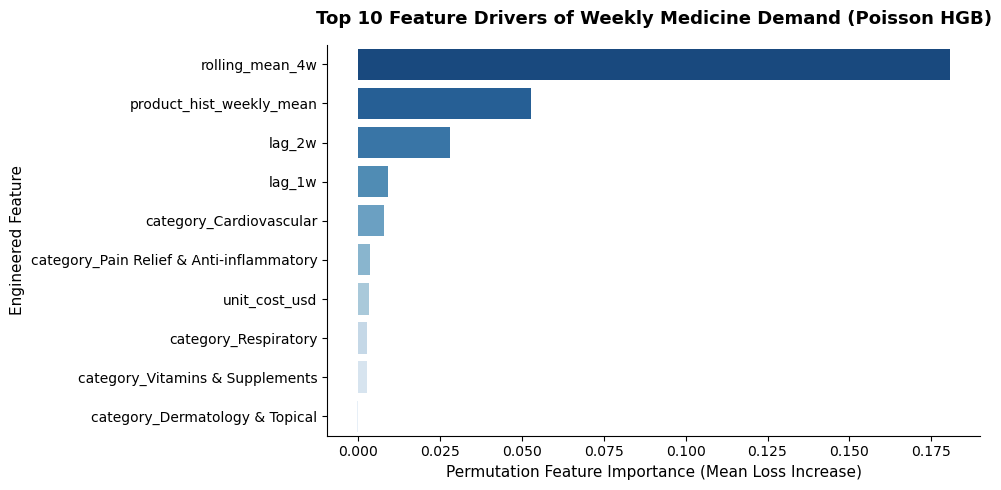

Primary Insight: Historical product demand velocity (product_hist_weekly_mean, lag_1w) and pricing dominate predictive power.


In [22]:
## Feature Importance & Model Interpretability
from sklearn.inspection import permutation_importance  # <-- MISSING IMPORT ADDED
#  Calculate Permutation Feature Importance for the Weekly Poisson Model
perm_importance = permutation_importance(
    hgb_weekly, X_test_w, y_test_w, n_repeats=10, random_state=42
)

# Extract and Rank Top 10 Features
importances = pd.Series(
    perm_importance.importances_mean, index=feature_cols_w
).sort_values(ascending=False).head(10)

#  Plot Top Feature Drivers
plt.figure(figsize=(10, 5))
sns.barplot(x=importances.values, y=importances.index, palette="Blues_r")
plt.title("Top 10 Feature Drivers of Weekly Medicine Demand (Poisson HGB)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Permutation Feature Importance (Mean Loss Increase)", fontsize=11)
plt.ylabel("Engineered Feature", fontsize=11)
sns.despine()
plt.tight_layout()
plt.show()

print("Primary Insight: Historical product demand velocity (product_hist_weekly_mean, lag_1w) and pricing dominate predictive power.")

In [23]:
# ==============================================================================
# CELL 4: OPERATIONAL RISK & WRITE-OFF LOSS QUANTIFICATION (WEEKLY)
# ==============================================================================

# 1. Generate 30-Day Forward Forecast for Every Product
# Grab the most recent weekly feature snapshot for each product
latest_features_w = (
    weekly_model_data.sort_values('transaction_date')
    .groupby('product_id')
    .last()
    .reset_index()
)

# Re-apply historical product mean mapping
latest_features_w['product_hist_weekly_mean'] = latest_features_w['product_id'].map(prod_weekly_mean)

# Filter feature matrix
drop_cols = ['product_id', 'product_name', 'transaction_date', 'weekly_units']
feature_cols_w = [c for c in latest_features_w.columns if c not in drop_cols]
X_latest_w = latest_features_w[feature_cols_w]

# Predict weekly demand and convert to 30-day forecast (30 days / 7 days = ~4.286 weeks)
predicted_weekly = np.clip(hgb_weekly.predict(X_latest_w), 0, None)

product_forecast_30d = pd.DataFrame({
    'product_id': latest_features_w['product_id'],
    'predicted_30d_demand_units': np.round(predicted_weekly * (30.0 / 7.0)).astype(int)
})

# 2. Merge Forecast into Active Batches Expiring in the Next 30 Days
analysis_date = pd.to_datetime('2026-10-26')
df_batches['days_to_expiry'] = (df_batches['expiry_date'] - analysis_date).dt.days

# Filter to near-expiry batches (0 to 30 days remaining) with stock on hand
near_expiry_batches = df_batches[
    (df_batches['days_to_expiry'] >= 0) & 
    (df_batches['days_to_expiry'] <= 30) & 
    (df_batches['current_stock_quantity'] > 0)
].copy()

# Merge product details and predicted 30-day demand
risk_audit = near_expiry_batches.merge(df_products, on='product_id', how='left')
risk_audit = risk_audit.merge(product_forecast_30d, on='product_id', how='left')

# 3. Calculate Impending Surplus & Financial Waste Exposure
# Surplus units = Current Stock - Expected 30-Day Demand
risk_audit['expected_expired_units'] = np.maximum(
    0,
    risk_audit['current_stock_quantity'] - risk_audit['predicted_30d_demand_units']
)

# Financial Loss in USD at wholesale cost
risk_audit['predicted_financial_waste_usd'] = (
    risk_audit['expected_expired_units'] * risk_audit['unit_cost_usd']
)

# Prescriptive Operational Action Rule
risk_audit['recommended_action'] = np.where(
    risk_audit['expected_expired_units'] > 0,
    'TRIGGER IMMEDIATE 30-40% CLEARANCE MARKDOWN',
    'MAINTAIN FULL RETAIL PRICE (WILL SELL OUT)'
)

# 4. Display Summary Audit Table
output_cols = [
    'batch_id',
    'product_name',
    'category',
    'days_to_expiry',
    'current_stock_quantity',
    'predicted_30d_demand_units',
    'expected_expired_units',
    'predicted_financial_waste_usd',
    'recommended_action'
]

print("=== OPERATIONAL EXPIRED STOCK PREVENTION AUDIT ===")
print(f"Total Batches Expiring in <=30 Days: {len(risk_audit)}")
print(f"Batches Guaranteed to Have Expired Waste: {(risk_audit['expected_expired_units'] > 0).sum()}")
print(f"Total Predicted Financial Waste (Cost): ${risk_audit['predicted_financial_waste_usd'].sum():,.2f}")
print("=" * 60)

display(risk_audit[output_cols].sort_values('predicted_financial_waste_usd', ascending=False))

# 5. Export Updated Results for Power BI Integration
risk_audit.to_csv('ml_forecast_expiry_risk.csv', index=False)
print("\nExported updated results to 'ml_forecast_expiry_risk.csv' for Power BI integration!")

=== OPERATIONAL EXPIRED STOCK PREVENTION AUDIT ===
Total Batches Expiring in <=30 Days: 10
Batches Guaranteed to Have Expired Waste: 7
Total Predicted Financial Waste (Cost): $14,884.73


,batch_id,product_name,category,days_to_expiry,current_stock_quantity,predicted_30d_demand_units,expected_expired_units,predicted_financial_waste_usd,recommended_action
7,BAT-2025-249,Vitamin C 500mg,Vitamins & Supplements,28,189,35,154,6344.80,TRIGGER IMMEDIATE 30-40% CLEARANCE MARKDOWN
1,BAT-2025-143,Aspirin 81mg,Pain Relief & Anti-inflammatory,20,250,89,161,4107.11,TRIGGER IMMEDIATE 30-40% CLEARANCE MARKDOWN
8,BAT-2025-257,Calcium + D3,Vitamins & Supplements,10,231,138,93,2192.94,TRIGGER IMMEDIATE 30-40% CLEARANCE MARKDOWN
2,BAT-2025-152,Amlodipine 5mg,Cardiovascular,7,188,44,144,1643.04,TRIGGER IMMEDIATE 30-40% CLEARANCE MARKDOWN
0,BAT-2025-114,Cephalexin 500mg,Antibiotics,13,241,47,194,543.20,TRIGGER IMMEDIATE 30-40% CLEARANCE MARKDOWN
3,BAT-2025-169,Clopidogrel 75mg,Cardiovascular,24,130,122,8,36.88,TRIGGER IMMEDIATE 30-40% CLEARANCE MARKDOWN
6,BAT-2025-239,Domperidone 10mg,Gastrointestinal,30,107,105,2,16.76,TRIGGER IMMEDIATE 30-40% CLEARANCE MARKDOWN
4,BAT-2025-223,Pantoprazole 40mg,Gastrointestinal,8,43,159,0,0.00,MAINTAIN FULL RETAIL PRICE (WILL SELL OUT)
5,BAT-2025-229,Ranitidine 150mg,Gastrointestinal,22,50,81,0,0.00,MAINTAIN FULL RETAIL PRICE (WILL SELL OUT)
9,BAT-2025-273,Omega-3 Fish Oil 1000mg,Vitamins & Supplements,13,49,49,0,0.00,MAINTAIN FULL RETAIL PRICE (WILL SELL OUT)



Exported updated results to 'ml_forecast_expiry_risk.csv' for Power BI integration!
